## Loading Assets

In [3]:
import pandas as pd
import numpy as np
import cv2
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,
roc_auc_score,confusion_matrix,roc_curve)

import matplotlib.pyplot as plt

from pathlib import Path
NOTEBOOK_DIR = Path.cwd()
EXPERIMENT_ROOT = NOTEBOOK_DIR.parent
import sys

if str(EXPERIMENT_ROOT) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_ROOT))

from paths import (DATASET_ROOT, GT_MASK_DIR)

In [4]:
csv_path = "./detection_scores.csv"
df = pd.read_csv(csv_path)

y_true = df["label"].values
y_scores = df["score"].values
# Threshold = 0.5
y_pred = (y_scores > 0.5).astype(np.uint8)
df.head()

# Real Images : 0
# Manipulated Images : 1

,image_name,label,score
0,1.jpg,0,0.151234
1,10.jpg,0,0.262128
2,100.jpg,0,0.292395
3,101.jpg,0,0.210152
4,102.jpg,0,0.148119


## Metrics and ROC

In [17]:
accuracy = accuracy_score(y_true,y_pred)
precision = precision_score(y_true,y_pred)
recall = recall_score(y_true,y_pred)
f1 = f1_score(y_true,y_pred)
auc = roc_auc_score(y_true,y_scores)

cm = confusion_matrix(y_true,y_pred)
TN, FP, FN, TP = cm.ravel()

print("===== CONFUSION MATRIX =====")

print(f"TN = {TN}")
print(f"FP = {FP}")
print(f"FN = {FN}")
print(f"TP = {TP}")

print()
print("===== DETECTION METRICS =====")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"AUC       : {auc:.4f}")

===== CONFUSION MATRIX =====
TN = 178
FP = 22
FN = 118
TP = 882

===== DETECTION METRICS =====
Accuracy  : 0.8833
Precision : 0.9757
Recall    : 0.8820
F1 Score  : 0.9265
AUC       : 0.9478


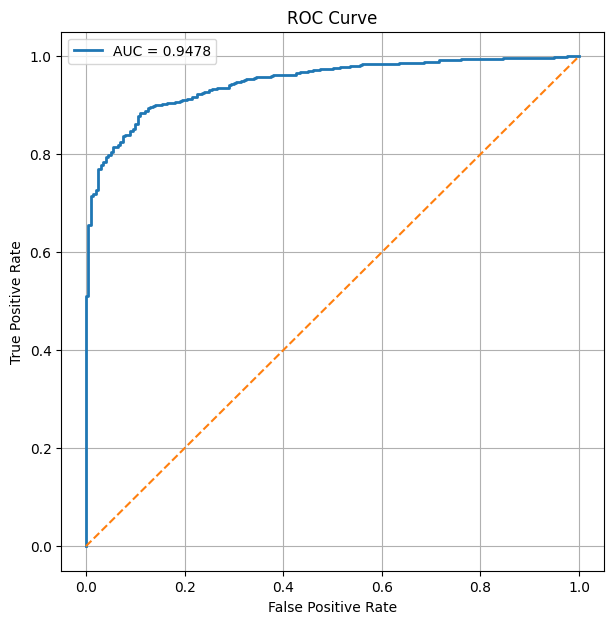

In [18]:
fpr, tpr, thresholds = roc_curve(y_true,y_scores)
plt.figure(figsize=(7, 7))

plt.plot(fpr,tpr,linewidth=2, label=f"AUC = {auc:.4f}")
plt.plot([0, 1],[0, 1],linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()
plt.grid()
plt.show()

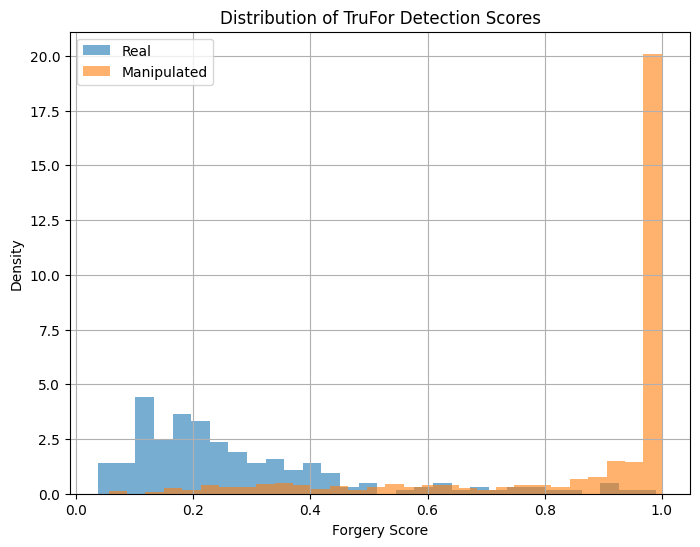

In [21]:
import matplotlib.pyplot as plt

real_scores = df[df["label"] == 0]["score"]
fake_scores = df[df["label"] == 1]["score"]

plt.figure(figsize=(8,6))

plt.hist(real_scores,bins=30,alpha=0.6,density=True,label="Real")
plt.hist(fake_scores,bins=30,alpha=0.6,density=True,label="Manipulated")

plt.xlabel("Forgery Score")
plt.ylabel("Density")
plt.title("Distribution of TruFor Detection Scores")

plt.legend()
plt.grid()
plt.show()

## Misclassification Analysis

In [19]:
misclassified = df[df["label"] != y_pred]
print(f"Misclassified examples: {len(misclassified)}")
print(f"FP = {FP}")
print(f"FN = {FN}")
print()

false_positives = df[(df["label"] == 0)&(y_pred == 1)]
print("===== FALSE POSITIVES : Real Images classified as Manipulated =====")
print(false_positives.sort_values(by = 'score', ascending= False).head())

print()
print("===== FALSE Negatives : Manipulated Images classified as Real =====")
false_negatives = df[(df["label"] == 1) & (y_pred == 0)]
print(false_negatives.sort_values(by = 'score', ascending= True).head())

Misclassified examples: 140
FP = 22
FN = 118

===== FALSE POSITIVES : Real Images classified as Manipulated =====
    image_name  label     score
120     27.jpg      0  0.990389
76     168.jpg      0  0.957741
140     45.jpg      0  0.912797
24     120.jpg      0  0.910656
134      4.jpg      0  0.903588

===== FALSE Negatives : Manipulated Images classified as Real =====
    image_name  label     score
400  137_1.png      1  0.055164
240  108_1.png      1  0.067115
588  170_4.png      1  0.076465
629  178_5.png      1  0.085636
612  175_3.png      1  0.121185


In [59]:
false_positives = df[(df["label"]==0)&(y_pred==1)].copy()
false_negatives = df[(df["label"]==1)&(y_pred==0)].copy()

top_fp = (false_positives.sort_values("score", ascending=False).head(6))
top_fn = (false_negatives.sort_values("score").head(6))

### False Positive Visualization

**False Postive:** Real Images classified as Manipulated

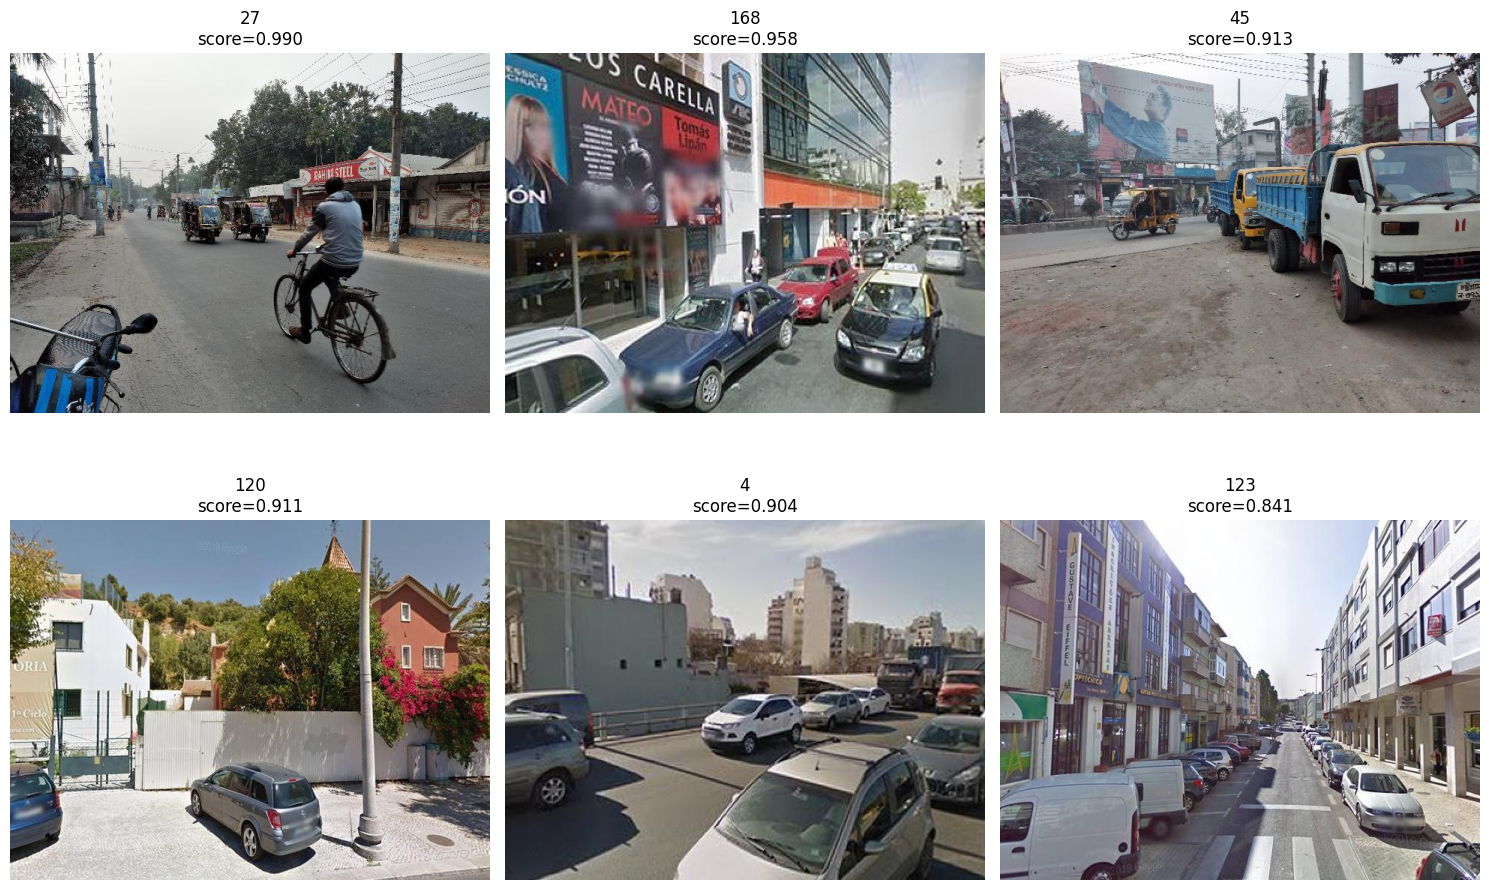

In [58]:
REAL_IMAGE_DIR = DATASET_ROOT / "pristine_images_used_for_manipulation"

fig, axes = plt.subplots(2,3,figsize=(15, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, top_fp.iterrows()):
    img_path = REAL_IMAGE_DIR / row.image_name
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)

    ax.set_title(f"{row.image_name[:-4]}\nscore={row.score:.3f}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### False Negative Analysis

**False Negative:** Manipulated Images classified as Real


In [63]:
import cv2
import pandas as pd

fn_with_area = false_negatives.copy()

mask_area_pixels = []
mask_area_percent = []

for _, row in fn_with_area.iterrows():

    mask_path = GT_MASK_DIR / row.image_name
    mask = cv2.imread(str(mask_path),cv2.IMREAD_GRAYSCALE)
    mask_binary = mask > 0

    manipulated_pixels = mask_binary.sum()

    total_pixels = mask_binary.shape[0] * mask_binary.shape[1]
    area_percentage = (manipulated_pixels /total_pixels) * 100
    mask_area_pixels.append( manipulated_pixels)
    mask_area_percent.append(area_percentage)

fn_with_area["mask_pixels"] = mask_area_pixels
fn_with_area["mask_area_percent"] = mask_area_percent

fn_with_area = (fn_with_area.sort_values( "mask_area_percent",ascending=True).reset_index(drop=True))
fn_with_area.head(10)

,image_name,label,score,mask_pixels,mask_area_percent
0,141_5.png,1,0.215576,141,0.061368
1,36_3.png,1,0.357379,287,0.084293
2,25_4.png,1,0.232635,122,0.101667
3,161_4.png,1,0.227729,183,0.152500
4,66_2.png,1,0.287675,491,0.159831
5,178_5.png,1,0.085636,201,0.167500
6,108_1.png,1,0.067115,202,0.168333
7,166_5.png,1,0.153147,246,0.205000
8,169_5.png,1,0.267584,295,0.245833
9,137_1.png,1,0.055164,317,0.264167


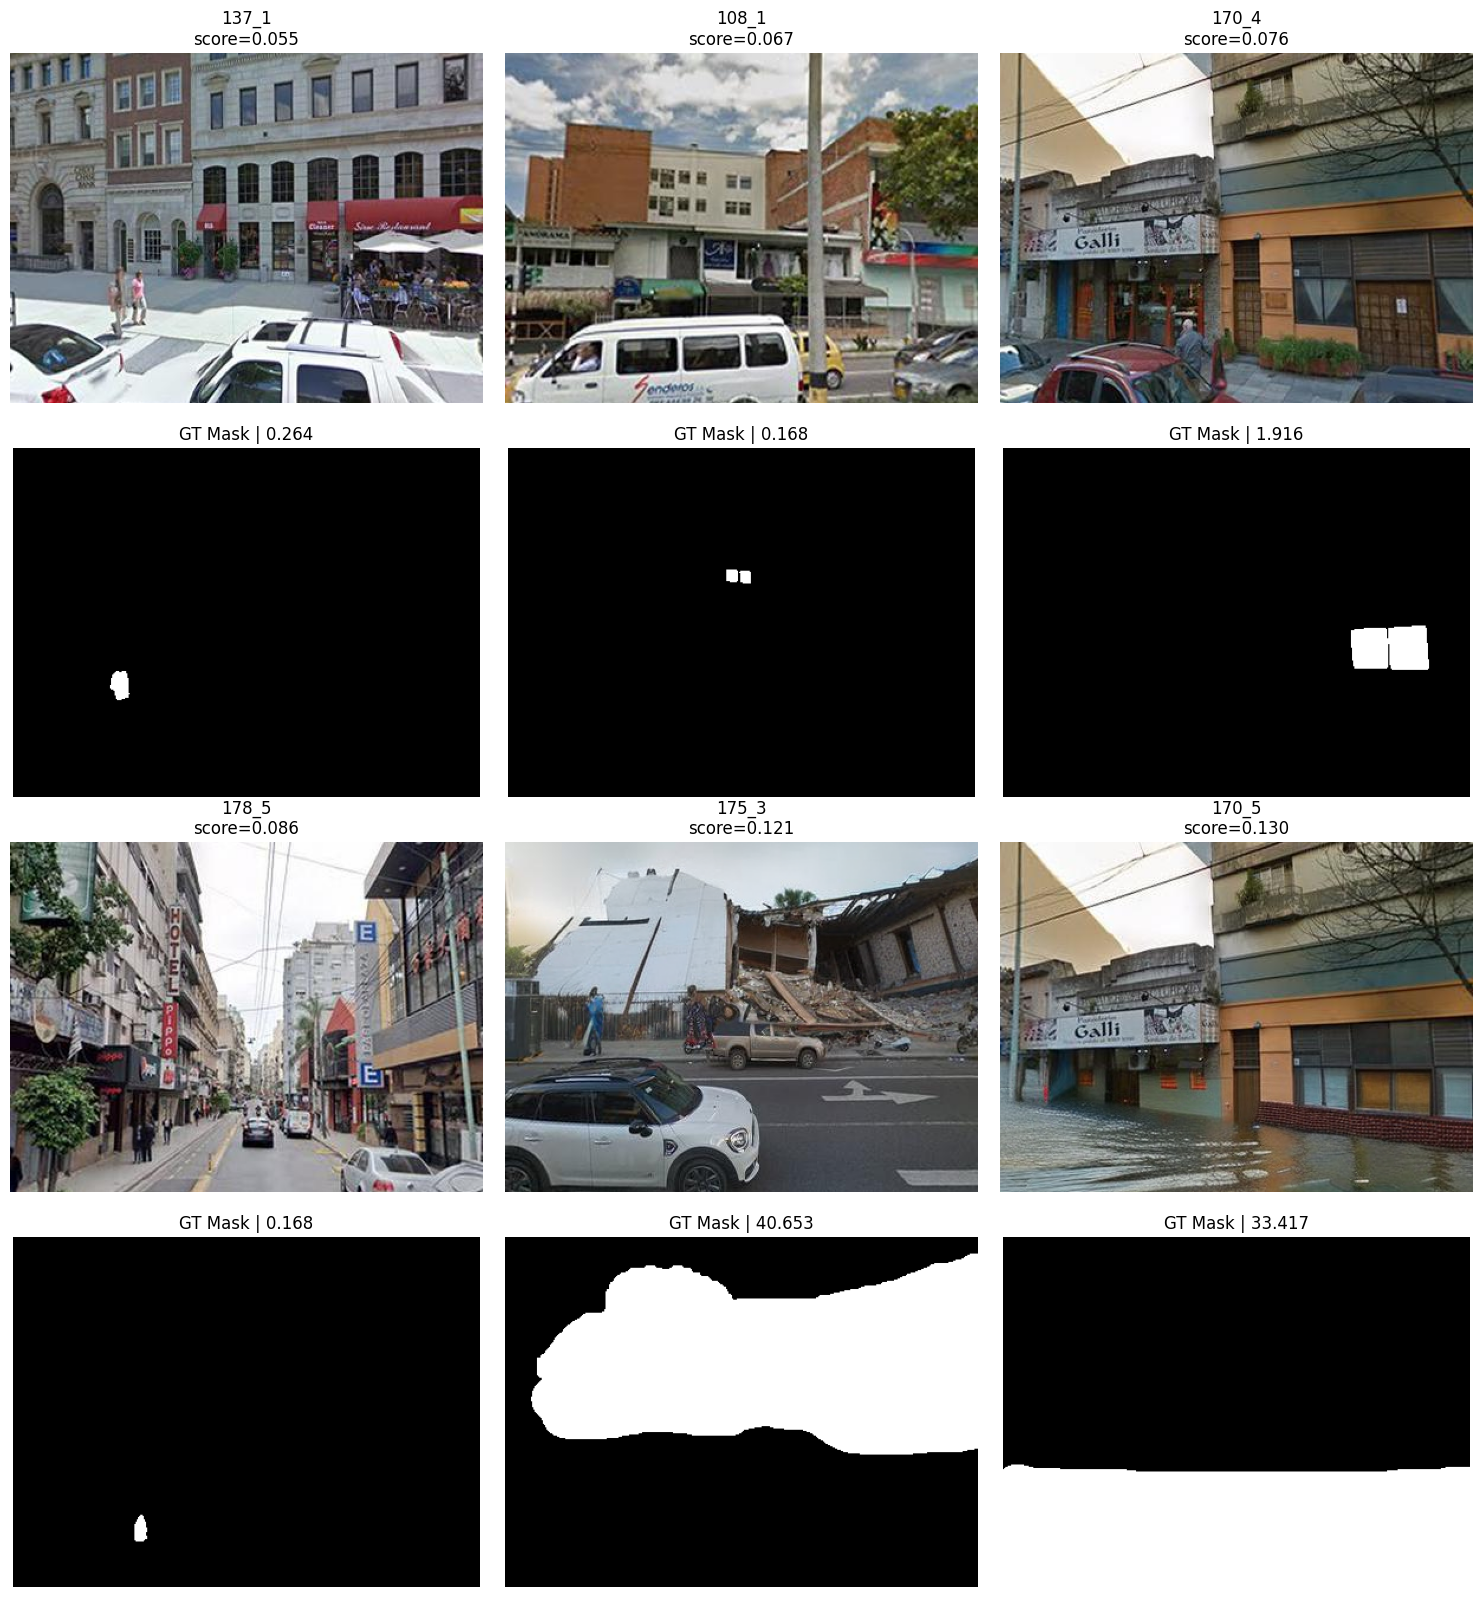

In [66]:
MANIP_IMAGE_DIR = DATASET_ROOT / "manipulated_images"

fig, axes = plt.subplots(4,3,figsize=(15, 16))
for i, (_, row) in enumerate(top_fn.iterrows()):
    col = i % 3

    # First 3 examples occupy rows 0 and 1
    # Next 3 occupy rows 2 and 3
    row_img = (i // 3) * 2
    row_mask = row_img + 1

    img_path = MANIP_IMAGE_DIR / row.image_name

    mask_path = GT_MASK_DIR / row.image_name

    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(str(mask_path),cv2.IMREAD_GRAYSCALE)
    mask_binary = mask > 0

    manipulated_pixels = mask_binary.sum()

    total_pixels = mask_binary.shape[0] * mask_binary.shape[1]
    area_percentage = (manipulated_pixels /total_pixels) * 100

    # Image
    axes[row_img, col].imshow(img)

    axes[row_img, col].set_title(f"{row.image_name[:-4]}\nscore={row.score:.3f}")
    axes[row_img, col].axis("off")

    # Mask
    axes[row_mask, col].imshow(mask,cmap="gray")
    axes[row_mask, col].set_title(f"GT Mask | {area_percentage:.3f}")
    axes[row_mask, col].axis("off")

plt.tight_layout()
plt.show()

## Masked Area Analysis

Analyzing how the TruFor Model performs on the CSI-IMD Dataset depending on the masked area in the image, <br>
that is edited portion area. For this analysis, only manipulated images are used.

In [5]:
import cv2
import numpy as np
import pandas as pd

# Only manipulated images
manip_df = df[df["label"] == 1].copy()

# Add prediction column
manip_df["prediction"] = y_pred[df["label"] == 1]

mask_pixels = []
mask_area_percent = []

for _, row in manip_df.iterrows():

    mask_path = GT_MASK_DIR / row.image_name
    mask = cv2.imread(str(mask_path),cv2.IMREAD_GRAYSCALE)
    mask_binary = mask > 0

    manipulated_pixels = mask_binary.sum()

    total_pixels = (mask_binary.shape[0]* mask_binary.shape[1])
    area_percentage = (manipulated_pixels/ total_pixels) * 100
    mask_pixels.append(manipulated_pixels)

    mask_area_percent.append(area_percentage)

manip_df["mask_pixels"] = mask_pixels
manip_df["mask_area_percent"] = mask_area_percent
manip_df["outcome"] = np.where(manip_df["prediction"] == 1,"TP","FN")
manip_df = (manip_df.sort_values("mask_area_percent").reset_index(drop=True))

manip_df.head()

,image_name,label,score,prediction,mask_pixels,mask_area_percent,outcome
0,141_5.png,1,0.215576,0,141,0.061368,FN
1,31_4.png,1,0.570675,1,173,0.075087,TP
2,46_3.png,1,0.898546,1,232,0.075521,TP
3,36_3.png,1,0.357379,0,287,0.084293,FN
4,39_1.png,1,0.670611,1,197,0.085742,TP


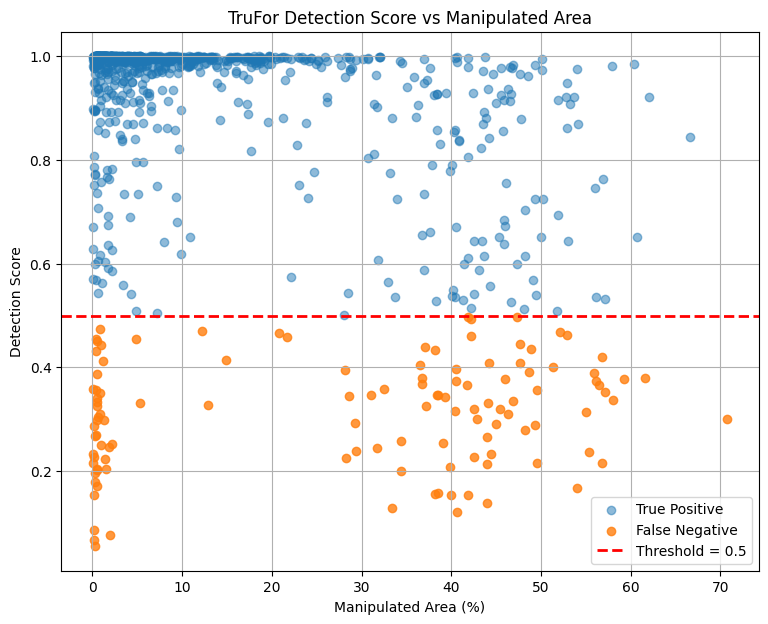

In [ ]:
# Although TruFor exhibits reduced sensitivity for manipulations occupying very small image regions, manipulated area alone does not explain detection failures. 
# Considerable score variability exists even among images with similar manipulated area percentages, and several false negatives correspond to large edited regions. 
# This indicates that additional factors such as manipulation characteristics and image content significantly influence image-level detection performance.

import matplotlib.pyplot as plt

tp_df = manip_df[manip_df["outcome"] == "TP"]
fn_df = manip_df[manip_df["outcome"] == "FN"]

plt.figure(figsize=(9,7))

plt.scatter(tp_df["mask_area_percent"],tp_df["score"],alpha=0.5,label="True Positive")
plt.scatter(fn_df["mask_area_percent"],fn_df["score"],alpha=0.8,label="False Negative")
plt.axhline(y=0.5,linestyle="--",linewidth=2,color="red",label="Threshold = 0.5")

plt.xlabel("Manipulated Area (%)")
plt.ylabel("Detection Score")
plt.title("TruFor Detection Score vs Manipulated Area")

plt.grid()
plt.legend()
plt.show()

In [95]:
area_pct = 10
print(f"Area: {area_pct}%")
print("False Negatives:",len(manip_df[(manip_df['outcome'] == 'FN') & (manip_df['mask_area_percent'] <= area_pct)]))
print("True Positives:",len(manip_df[(manip_df['outcome'] == 'TP') & (manip_df['mask_area_percent'] <= area_pct)]))

Area: 10%
False Negatives: 40
True Positives: 589


In [94]:
area_pct_min = 30
area_pct_max = 60
print(f"Area: [{area_pct_min}, {area_pct_max}]%")
print("False Negatives:",len(manip_df[(manip_df['outcome'] == 'FN') & (area_pct_min <= manip_df['mask_area_percent']) & ( manip_df['mask_area_percent'] <= area_pct_max)]))
print("True Positives:",len(manip_df[(manip_df['outcome'] == 'TP') & (area_pct_min <= manip_df['mask_area_percent']) & (manip_df['mask_area_percent'] <= area_pct_max)]))

Area: [30, 60]%
False Negatives: 66
True Positives: 123


### Copying False Negative Images

In [97]:
from pathlib import Path
import shutil

# ----------------------------------------------------
# Destination directories
# ----------------------------------------------------

processed_dir = EXPERIMENT_ROOT / "processed"
small_img_dir = (processed_dir/ "false_negatives_small_area"/ "images")
small_mask_dir = (processed_dir/ "false_negatives_small_area"/ "masks")
large_img_dir = (processed_dir/ "false_negatives_large_area"/ "images")
large_mask_dir = (processed_dir/ "false_negatives_large_area"/ "masks")

# Create directories
small_img_dir.mkdir(parents=True,exist_ok=True)
small_mask_dir.mkdir(parents=True,exist_ok=True)
large_img_dir.mkdir(parents=True,exist_ok=True)
large_mask_dir.mkdir(parents=True,exist_ok=True)

# ----------------------------------------------------
# Cluster definitions
# ----------------------------------------------------

small_fn = fn_with_area[fn_with_area["mask_area_percent"] < 10]
large_fn = fn_with_area[(fn_with_area["mask_area_percent"] >= 30)&(fn_with_area["mask_area_percent"] <= 60)]

print(f"Small-area FN: {len(small_fn)}")
print(f"Large-area FN: {len(large_fn)}")

Small-area FN: 40
Large-area FN: 66


In [98]:
# ----------------------------------------------------
# Copy small-area failures
# ----------------------------------------------------

for _, row in small_fn.iterrows():
    filename = row.image_name
    shutil.copy2(MANIP_IMAGE_DIR / filename,small_img_dir / filename)
    shutil.copy2(GT_MASK_DIR / filename,small_mask_dir / filename)

# ----------------------------------------------------
# Copy large-area failures
# ----------------------------------------------------

for _, row in large_fn.iterrows():
    filename = row.image_name
    shutil.copy2(MANIP_IMAGE_DIR / filename,large_img_dir / filename)
    shutil.copy2(GT_MASK_DIR / filename,large_mask_dir / filename)
    
print("Finished copying false-negative clusters.")

Finished copying false-negative clusters.


## Semantic Level Analysis

In [ ]:
fn_df = manip_df[manip_df["outcome"] == "FN"].copy()
fn_df["semantic_rank"] = (fn_df["image_name"].str.replace(".png", "", regex=False).str.split("_").str[1].astype(int))
semantic_counts = (fn_df["semantic_rank"].value_counts().sort_index())

# False negatives increase with semantic significance. (Monotonically)
print(semantic_counts)

semantic_rank
1     9
2     8
3    27
4    36
5    38
Name: count, dtype: int64


In [8]:
def area_cluster(area):
    if area < 10:
        return "Small (<10%)"
    elif area <= 30:
        return "Medium (10-30%)"
    else:
        return "Large (>30%)"

manip_df["area_cluster"] = (manip_df["mask_area_percent"].apply(area_cluster))
manip_df["semantic_rank"] = (manip_df["image_name"].str.replace(".png","",regex=False).str.split("_").str[1].astype(int))
fn_df = manip_df[manip_df["outcome"]=="FN"].copy()

In [ ]:
# When a large portion of the image is manipulated, TruFor mainly fails on semantically important edits rather than trivial ones.
# For tiny manipulated regions, the amount of manipulated area itself seems to be the limiting factor. Semantics do not matter here.

# Failure Mode A: Small Manipulations
# Failure is largely geometric:
    # - weak signal,
    # - insufficient spatial support.

# Failure Mode B: Large Manipulations
# Failure associated with edits of increasing semantic significance. (Rank 3-5)

cluster_semantic_table = pd.crosstab(fn_df["area_cluster"],fn_df["semantic_rank"])
cluster_semantic_table

semantic_rank,1,2,3,4,5
area_cluster,,,,,
Large (>30%),0,3,18,22,25
Medium (10-30%),0,1,3,4,2
Small (<10%),9,4,6,10,11
